# 01 · Exploratory data analysis (before and after cleaning)

**Goal:** show what was wrong with the raw data, what the cleaning fixed, and what the cleaned data we model looks like.

| Section | Details |
|---|---|
| **Part A: before** | raw `data/raw/Combined_dataset.csv` (England, USA, Ireland, Canada), to show the problems |
| **Part B: after** | cleaned `data/processed/final_dataset.csv`, to show what we model |
| **Part C** | before vs after, side by side |
| **Figures** | save to `results/figures/eda_*.png` |

**Raw file:** download `Combined_dataset.csv` from the figshare link in the README and put it in `data/raw/` (320 MB, not committed).

## 0. Setup

Imports, paths and settings.

In [1]:
import os, sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import (
    load_combined_for_countries, clean_column_names, DEFAULT_COUNTRIES,
    PARAM_COLS, SENSOR_COLS, PHYSICAL_RULES,
)

RAW_PATH = "../data/raw/Combined_dataset.csv"
FINAL_PATH = "../data/processed/final_dataset.csv"
FIG_DIR = "../results/figures"
os.makedirs(FIG_DIR, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Part A · Before: the raw data

## A1. Load the raw data
Load the four countries with `load_combined_for_countries`, tidy the names with `clean_column_names`, parse `date`. Show shape and `head()`. Free the memory at the end of Part A (`del raw`), the table is large.

In [2]:
raw = load_combined_for_countries(RAW_PATH, DEFAULT_COUNTRIES)
raw = clean_column_names(raw)
raw["date"] = pd.to_datetime(raw["date"], format="%d-%m-%Y", errors="coerce")
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]:,} columns")
display(raw.head())

Raw shape: 2,781,980 rows × 14 columns


,country,site_id,waterbody_type,date,ammonia_mg_l,bod_mg_l,dissolved_oxygen_mg_l,orthophosphate_mg_l,ph,temperature_c,nitrogen_mg_l,nitrate_mg_l,target_ccme_value,target_ccme_class
0,Canada,SE649035-145565,River,1974-01-12,0.059248,1.30,8.1500,0.011917,8.07500,9.885,0.343917,11.73155,100.0,Excellent
1,Canada,SE649035-145565,River,1975-01-12,0.039821,1.38,7.8000,0.009417,7.73333,10.150,0.449083,11.82009,100.0,Excellent
2,Canada,SE649035-145565,River,1976-01-12,0.031341,2.23,7.8000,0.011000,7.46667,10.235,0.220750,14.87472,100.0,Excellent
3,Canada,SE649035-145565,River,1977-01-12,0.020501,1.61,8.1500,0.012333,7.78333,11.116,0.572250,15.89293,100.0,Excellent
4,Canada,SE649035-145565,River,1978-01-12,0.020023,1.64,4.3708,0.006182,7.10000,7.068,0.371091,15.22888,100.0,Excellent


## A2. Rows per country and water type
Which countries dominate, and which water types exist? Cross-tab and % of rows per country.

In [3]:
display(pd.crosstab(raw["country"], raw["waterbody_type"], margins=True))
country_share = (raw["country"].value_counts(normalize=True).mul(100).round(2)
                 .rename("share_of_rows_percent").to_frame())
display(country_share)

waterbody_type,Canal,Coastal,Drainage,Effluent,Estuarine,Lake,Marine,River,Sea Water,Sewage,Transitional,All
country,,,,,,,,,,,,
Canada,0,2,0,0,0,602,0,3288,0,0,57,3949
England,28574,0,10205,601550,49375,33771,309,1349576,32061,23777,0,2129198
Ireland,0,2817,0,0,0,24465,0,203519,0,0,4218,235019
USA,0,0,0,0,0,94765,22853,296196,0,0,0,413814
All,28574,2819,10205,601550,49375,153603,23162,1852579,32061,23777,4275,2781980


,share_of_rows_percent
country,
England,76.54
USA,14.87
Ireland,8.45
Canada,0.14


**What we see → What we do about it:** The raw table is split very unevenly between countries, so England and Ireland will decide most of what the plots and the model scores show. After cleaning the same pattern is there: England 69.3%, Ireland 27.1%, USA 2.6% and Canada 1.0% of the rows. So we do not trust one overall score. We also report the results for each country.

## A3. Effluent, sewage and drainage
Share of rows with `waterbody_type` Effluent, Sewage or Drainage, per country (bar chart). These are discharges, not surface water.

,non_surface_rows_percent
country,
England,29.85
USA,0.00
Ireland,0.00
Canada,0.00


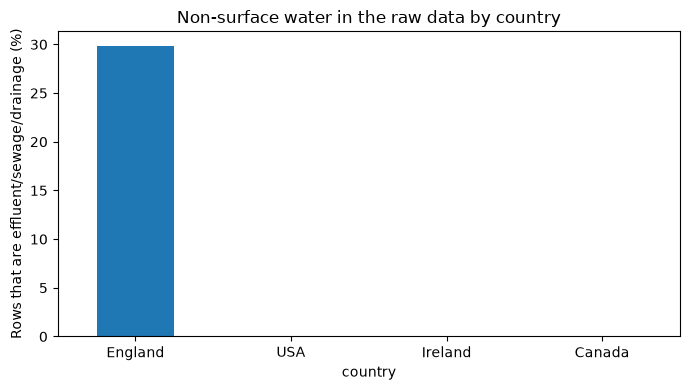

In [4]:
non_surface = raw[raw["waterbody_type"].isin(["Effluent", "Sewage", "Drainage"])]
share = (non_surface.groupby("country").size().div(raw.groupby("country").size()).mul(100)
         .reindex(DEFAULT_COUNTRIES).fillna(0))
display(share.rename("non_surface_rows_percent").round(2).to_frame())
ax = share.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Rows that are effluent/sewage/drainage (%)")
ax.set_title("Non-surface water in the raw data by country")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_a3_non_surface.png"), dpi=200); plt.show()

**What we see → What we do about it:** Effluent, sewage and drainage samples are water coming out of pipes and treatment works, not rivers, lakes or coasts. They are a big part of the raw data (635,532 rows were removed in total) and would make the water look worse than it is in nature. We remove them, because our project is about surface water.

## A4. Filled-in values (strongest plot)
Histograms of dissolved oxygen, pH and temperature for **England rivers**. Spikes at one exact value are placeholders inserted by the dataset authors. Tip: clip to the 0.5%–99.5% quantiles so the spikes stay visible.

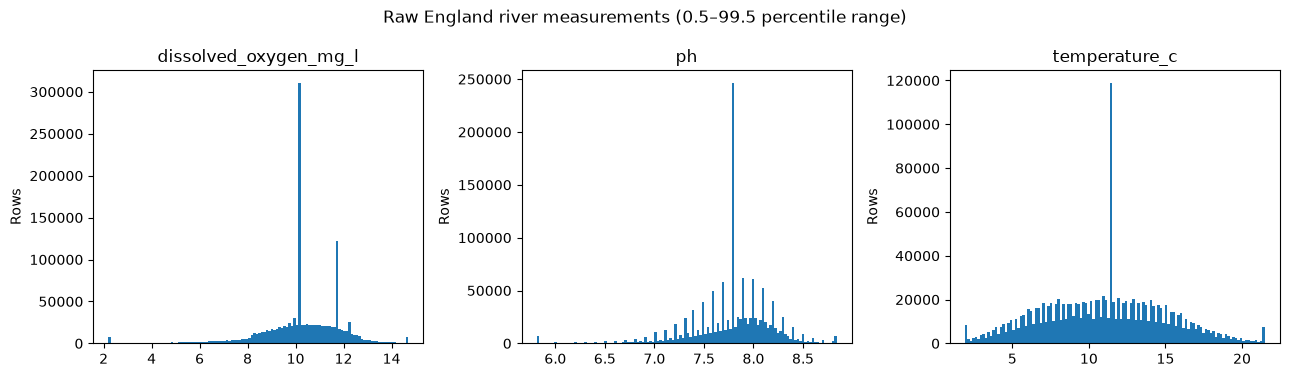

In [5]:
eng = raw[(raw["country"] == "England") & (raw["waterbody_type"] == "River")].copy()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, SENSOR_COLS):
    x = eng[col].dropna()
    if len(x):
        lo, hi = x.quantile([0.005, 0.995]); x = x.clip(lo, hi)
        ax.hist(x, bins=120)
    ax.set_title(col); ax.set_ylabel("Rows")
fig.suptitle("Raw England river measurements (0.5–99.5 percentile range)")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_a4_raw_spikes.png"), dpi=200); plt.show()

**What we see → What we do about it:** Look for very tall thin bars at one exact value. Real measurements spread out smoothly, so a tall spike means someone filled the gaps with the same number again and again (for example dissolved oxygen 10.2 in 360,401 England rows). These are not real readings. We find these repeated values and mark them as missing.

## A4b. Share of rows that are the most common value
Table: for each of the 8 parameters, % of rows equal to the single most common value, and to the 2nd most common (England rivers). Then the same for every country.

In [6]:
def common_value_table(frame, group_cols=None):
    groups = [("England rivers", frame)] if group_cols is None else list(frame.groupby(group_cols, dropna=False))
    rows = []
    for group, sub in groups:
        for col in PARAM_COLS:
            vc = sub[col].dropna().value_counts(normalize=True)
            rows.append({"group": group, "parameter": col,
                         "most_common_value": vc.index[0] if len(vc) else np.nan,
                         "most_common_share_percent": round(100*vc.iloc[0], 2) if len(vc) else np.nan,
                         "second_common_value": vc.index[1] if len(vc)>1 else np.nan,
                         "second_common_share_percent": round(100*vc.iloc[1], 2) if len(vc)>1 else np.nan})
    return pd.DataFrame(rows)
eng_rivers = raw[(raw["country"] == "England") & (raw["waterbody_type"] == "River")]
display(common_value_table(eng_rivers))
display(common_value_table(raw, "country"))

,group,parameter,most_common_value,most_common_share_percent,second_common_value,second_common_share_percent
0,England rivers,ammonia_mg_l,0.03,34.51,0.098000,3.30
1,England rivers,bod_mg_l,2.70,43.89,1.000000,11.10
2,England rivers,dissolved_oxygen_mg_l,10.20,22.95,11.684103,7.71
3,England rivers,orthophosphate_mg_l,0.02,9.86,0.144000,9.68
4,England rivers,ph,7.78,13.81,7.900000,3.99
5,England rivers,temperature_c,11.46,7.34,10.000000,0.77
6,England rivers,nitrogen_mg_l,5.00,7.47,0.200000,4.45
7,England rivers,nitrate_mg_l,4.50,18.36,0.196000,2.76


,group,parameter,most_common_value,most_common_share_percent,second_common_value,second_common_share_percent
0,Canada,ammonia_mg_l,0.100000,12.28,0.050000,6.18
1,Canada,bod_mg_l,2.133330,20.82,2.000000,14.74
2,Canada,dissolved_oxygen_mg_l,9.824000,17.62,11.684103,5.95
3,Canada,orthophosphate_mg_l,0.061000,19.09,0.200000,6.91
4,Canada,ph,7.790000,33.93,7.900000,0.89
5,Canada,temperature_c,12.000000,14.16,13.600000,0.46
6,Canada,nitrogen_mg_l,0.400000,70.22,0.002500,0.30
7,Canada,nitrate_mg_l,5.836820,5.75,5.000000,3.62
8,England,ammonia_mg_l,0.030000,24.32,0.500000,7.15
9,England,bod_mg_l,2.700000,32.21,1.000000,8.37


**What we see → What we do about it:** For each parameter this table shows how much of the data is one single value. If one value is a large share of the rows, it is probably filler. This is only a warning sign, not proof, because real values can repeat too. So we also check the country and water type before marking a value as missing.

## A5. Impossible values and duplicates
Count rows outside the physical ranges in `PHYSICAL_RULES` (e.g. temperature above 40 °C, pH outside 0–14) and exact duplicate rows.

In [7]:
rows = []
for col, (lo, hi, reason) in PHYSICAL_RULES.items():
    if col in raw.columns:
        bad = raw[col].notna() & ((raw[col] < lo) | (raw[col] > hi))
        rows.append({"parameter": col, "allowed_range": f"{lo} to {hi}",
                     "outside_range_rows": int(bad.sum()), "reason": reason})
display(pd.DataFrame(rows))
dup_count = int(raw.duplicated().sum())
print(f"Exact duplicate rows: {dup_count:,} ({dup_count/len(raw)*100:.2f}% of raw rows)")

,parameter,allowed_range,outside_range_rows,reason
0,ph,0.0 to 14.0,505,Outside the physical pH scale; instrument error
1,temperature_c,-5.0 to 40.0,7285,Surface water outside -5..40 C is a unit error...
2,dissolved_oxygen_mg_l,0.0 to 25.0,0,Above ~25 mg/L is not physically possible in s...
3,bod_mg_l,0.0 to 150.0,13364,"Above 150 mg/L looks like effluent, not surfac..."
4,ammonia_mg_l,0.0 to 100.0,1238,Negative or extreme concentrations are errors
5,orthophosphate_mg_l,0.0 to 50.0,312,Negative or extreme concentrations are errors
6,nitrogen_mg_l,0.0 to 200.0,0,Negative or extreme concentrations are errors
7,nitrate_mg_l,0.0 to 200.0,0,Negative or extreme concentrations are errors


Exact duplicate rows: 9,951 (0.36% of raw rows)


**What we see → What we do about it:** Some values cannot be real, for example a pH above 14 or a temperature above 40 °C, and some rows are exact copies of other rows (7,277 were removed). These would give a wrong picture or count the same sample twice. We remove them.

## A6. Years covered
Samples per year (bar chart). How many rows are before 2000? Why is the data sparse early on?

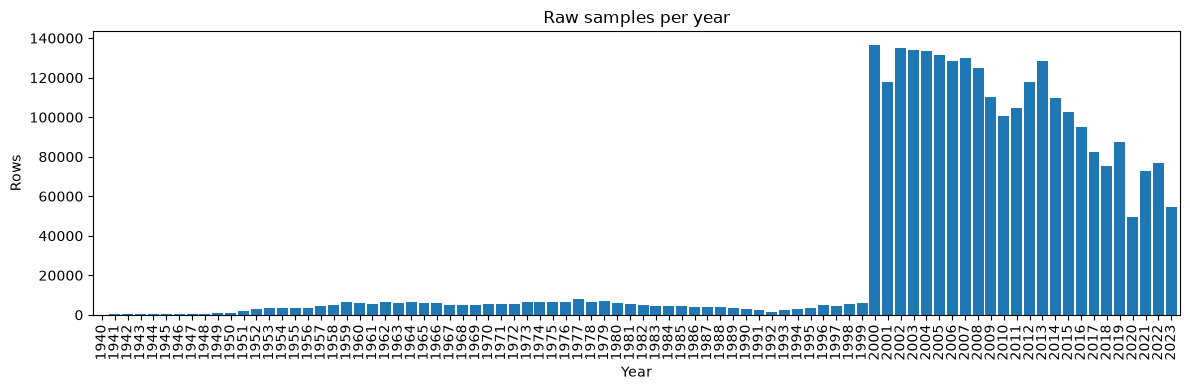

Rows before 2000: 243,089


In [8]:
year_counts = raw["date"].dt.year.value_counts().sort_index()
ax = year_counts.plot(kind="bar", figsize=(12, 4), width=.85)
ax.set_xlabel("Year"); ax.set_ylabel("Rows"); ax.set_title("Raw samples per year")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "eda_a6_raw_years.png"), dpi=200); plt.show()
print(f"Rows before 2000: {(raw['date'].dt.year < 2000).sum():,}")

**What we see → What we do about it:** The bar chart shows how many samples there are in each year. The early years are thin and uneven, so we keep only 2000 onwards (243,089 earlier rows were removed). This keeps the whole project on one clear time period.

Keep what Part C needs from the raw table (missing % per parameter, row count, rows per country, England-river dissolved oxygen), then `del raw`.

In [9]:
raw_missing = raw[PARAM_COLS].isna().mean().mul(100).round(2)
raw_n = len(raw)
raw_cols = raw.shape[1]
raw_by_country = raw["country"].value_counts()
raw_do_eng = raw.loc[(raw["country"] == "England") & (raw["waterbody_type"] == "River"), "dissolved_oxygen_mg_l"].copy()
del eng, eng_rivers, non_surface, share, year_counts
print("Saved raw summary values for Part C; raw table will now be released from memory.")
del raw

Saved raw summary values for Part C; raw table will now be released from memory.


# Part B · After: the cleaned data we model

## B1. Load `final_dataset.csv`
The only processed file. Show shape, number of stations, year range, `head()`, dtypes. Columns `split` (by station) and `split_time` (by year) label each row.

In [10]:
df = pd.read_csv(FINAL_PATH, parse_dates=["date"])
print(f"Cleaned shape: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
print(f"Unique stations: {df['site_id'].nunique():,}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
display(df.head())
display(df.dtypes.to_frame("dtype"))

Cleaned shape: 259,774 rows × 19 columns
Unique stations: 9,940
Date range: 2000-01-04 to 2023-12-05


,country,site_id,waterbody_type,date,year,month,ammonia_mg_l,bod_mg_l,dissolved_oxygen_mg_l,orthophosphate_mg_l,ph,temperature_c,nitrogen_mg_l,nitrate_mg_l,n_genuine_params,target_ccme_value,target_ccme_class,split,split_time
0,Canada,Canada|LI110048,River,2000-01-12,2000,1,0.0515,3.9076,NaN,0.01,8.3700,10.00,0.2417,9.7394,7,100.0,Excellent,train,train
1,Canada,Canada|LI110048,River,2001-01-12,2001,1,0.0644,3.3307,8.8000,0.01,8.1667,10.27,0.2760,10.6248,8,100.0,Excellent,train,train
2,Canada,Canada|LI110048,River,2002-01-12,2002,1,0.0773,3.1916,10.0333,0.01,8.0167,10.00,0.3190,8.7212,8,100.0,Excellent,train,train
3,Canada,Canada|LI110048,River,2003-01-12,2003,1,0.0902,3.7739,11.4750,0.01,NaN,8.68,0.2020,9.5180,7,100.0,Excellent,train,train
4,Canada,Canada|LI110048,River,2004-01-12,2004,1,0.1030,5.0600,11.7333,0.01,8.1583,8.43,0.3550,8.6326,8,100.0,Excellent,train,train


,dtype
country,str
site_id,str
waterbody_type,str
date,datetime64[us]
year,int64
month,int64
ammonia_mg_l,float64
bod_mg_l,float64
dissolved_oxygen_mg_l,float64
orthophosphate_mg_l,float64


## B2. Same histograms after cleaning
Repeat the A4 plot on the cleaned data (England rivers). The spikes should be gone. Use the same x-range as A4.

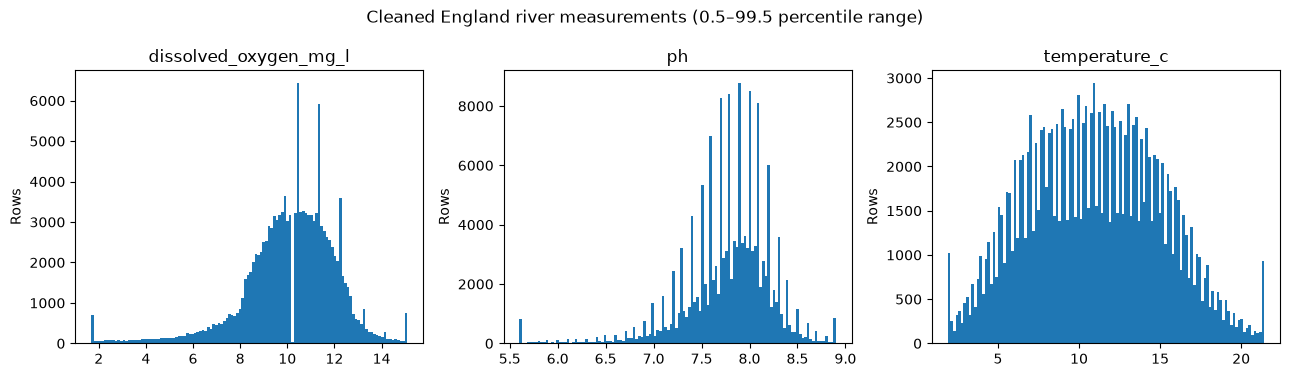

In [11]:
eng2 = df[(df["country"] == "England") & (df["waterbody_type"] == "River")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, SENSOR_COLS):
    x = eng2[col].dropna()
    if len(x):
        lo, hi = x.quantile([0.005, 0.995]); x = x.clip(lo, hi)
        ax.hist(x, bins=120)
    ax.set_title(col); ax.set_ylabel("Rows")
fig.suptitle("Cleaned England river measurements (0.5–99.5 percentile range)")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_b2_clean_hists.png"), dpi=200); plt.show()

**What we see → What we do about it:** Compare these bars with Part A. The tall spikes should now be gone. The values we removed are now empty (missing) instead of fake numbers. These empty values are filled later, using the training data only.

## B3. Missing values per parameter and country
Table (or heatmap) of % missing for the 8 parameters, per country. NaN here means "no real measurement": it was either a filler value we removed, or the parameter was never measured there.

,ammonia_mg_l,bod_mg_l,dissolved_oxygen_mg_l,orthophosphate_mg_l,ph,temperature_c,nitrogen_mg_l,nitrate_mg_l
country,,,,,,,,
Canada,0.96,2.65,13.31,19.27,26.69,2.38,76.54,1.54
England,31.67,52.98,19.94,0.95,3.54,0.04,1.03,15.02
Ireland,23.10,45.63,31.05,17.44,0.03,1.96,15.03,49.16
USA,44.16,100.00,3.00,3.08,69.46,0.90,26.11,2.07


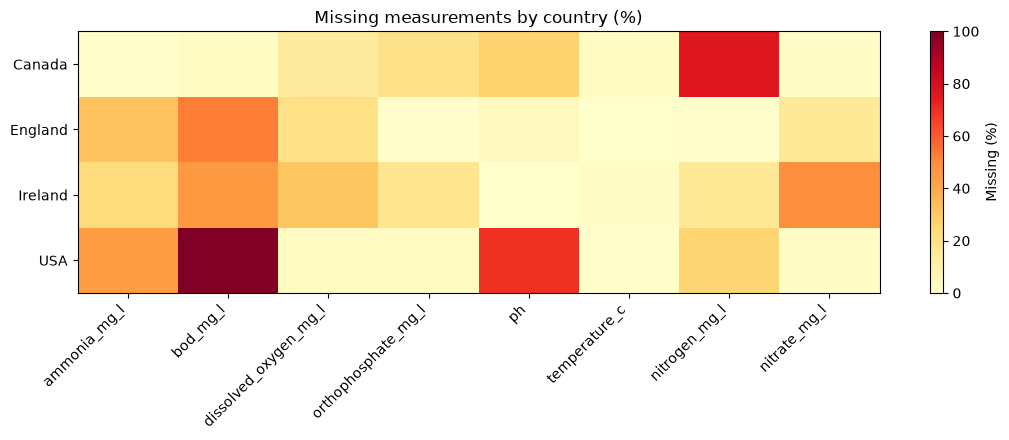

In [12]:
miss = df.groupby("country")[PARAM_COLS].apply(lambda g: g.isna().mean().mul(100).round(2))
display(miss.rename(columns={c: c for c in PARAM_COLS}))
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(miss.values, aspect="auto", vmin=0, vmax=100, cmap="YlOrRd")
ax.set_xticks(range(len(PARAM_COLS)), PARAM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(miss.index)), miss.index)
ax.set_title("Missing measurements by country (%)")
fig.colorbar(im, ax=ax, label="Missing (%)"); fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "eda_b3_missing_heatmap.png"), dpi=200); plt.show()

**What we see → What we do about it:** A missing value does not always mean a filler number. It can also mean the parameter was never measured at that place. For example, BOD is missing in 100% of the USA rows, nitrogen in 76.5% of Canada rows and pH in 69.5% of USA rows. Across all rows BOD is missing in 51.7%, ammonia in 29.4% and nitrate in 23.8%. Temperature (0.6%) and pH (4.5%) are almost always there. Because of this the model fills empty values using the training data only, and it also gets a flag that says the value was missing.

## B4. The target: CCME index
`target_ccme_value` (0–100): overall histogram and per country. Note the share of rows exactly equal to 100 and the class split in `target_ccme_class`.

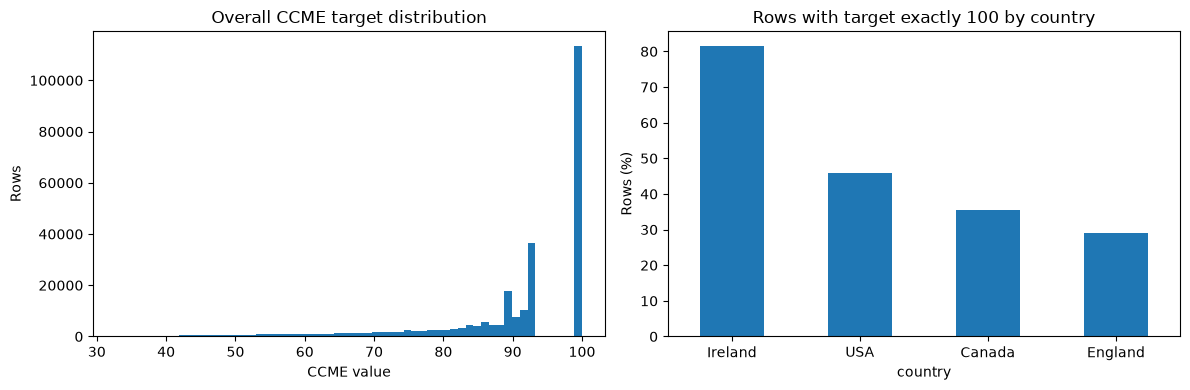

Target exactly 100: 43.68%


,percent
target_ccme_class,
Excellent,43.68
Good,39.85
Fair,9.59
Marginal,6.12
Poor,0.76


In [13]:
t = "target_ccme_value"
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[t].dropna(), bins=60)
axes[0].set_title("Overall CCME target distribution"); axes[0].set_xlabel("CCME value"); axes[0].set_ylabel("Rows")
share100 = df.assign(is_100=df[t].eq(100)).groupby("country")["is_100"].mean().mul(100).sort_values(ascending=False)
share100.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Rows with target exactly 100 by country"); axes[1].set_ylabel("Rows (%)")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_b4_target.png"), dpi=200); plt.show()
print(f"Target exactly 100: {df[t].eq(100).mean()*100:.2f}%")
display((df["target_ccme_class"].value_counts(normalize=True).mul(100).round(2)).rename("percent").to_frame())

**What we see → What we do about it:** The score stops at 100, so a lot of rows pile up there: 43.7% of all rows are exactly 100. Ireland is the most extreme (81.6%), England the least (28.9%). By class: Excellent 43.7%, Good 39.9%, Fair 9.6%, Marginal 6.1% and only 0.8% Poor. So there is very little data on bad water, which makes it hard to predict. That is why we also check the errors for each quality level, not only one overall score.

## B5. What drives the target? (why five parameters are held out)
Correlation (Spearman) of each of the 8 parameters with the target, as a bar chart. The index is calculated from these 8 parameters, which is why only DO, pH and temperature are model inputs (`03_features.ipynb`, section 2).

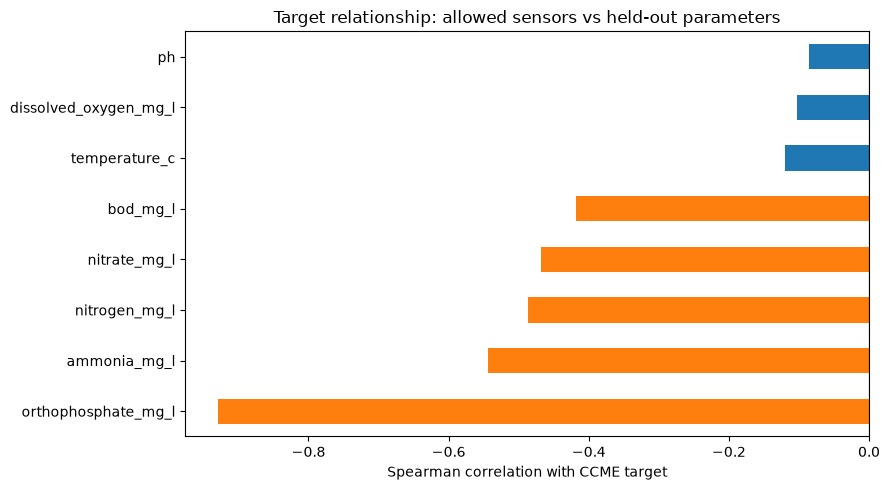

,spearman_with_target
orthophosphate_mg_l,-0.929347
ammonia_mg_l,-0.543491
nitrogen_mg_l,-0.486048
nitrate_mg_l,-0.468473
bod_mg_l,-0.418399
temperature_c,-0.119558
dissolved_oxygen_mg_l,-0.102448
ph,-0.085545


Blue = allowed sensor inputs; orange = held-out parameters to reduce target leakage.


In [14]:
corr = df[PARAM_COLS + ["target_ccme_value"]].corr(method="spearman")["target_ccme_value"].drop("target_ccme_value").sort_values()
colors = ["tab:blue" if c in SENSOR_COLS else "tab:orange" for c in corr.index]
fig, ax = plt.subplots(figsize=(9, 5))
corr.plot(kind="barh", ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=.8); ax.set_xlabel("Spearman correlation with CCME target")
ax.set_title("Target relationship: allowed sensors vs held-out parameters")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_b5_corr.png"), dpi=200); plt.show()
display(corr.rename("spearman_with_target").to_frame())
print("Blue = allowed sensor inputs; orange = held-out parameters to reduce target leakage.")

**What we see → What we do about it:** Orthophosphate is by far the strongest link with the score (−0.93), then ammonia (−0.54), nitrogen (−0.49), nitrate (−0.47) and BOD (−0.42). The three sensor readings are weak by themselves: dissolved oxygen −0.10, pH −0.09 and temperature −0.12. The five strong ones are the main ingredients of the formula. If the model sees them, it just recomputes the score. So we hide them and keep only the sensors. (A negative value means: more of it, lower score. Correlation does not mean cause.)

## B6. Samples per year and rows per station
Bar chart of rows per year; histogram of rows per station (clip at 60). Many stations have few rows, which is why the split is by station.

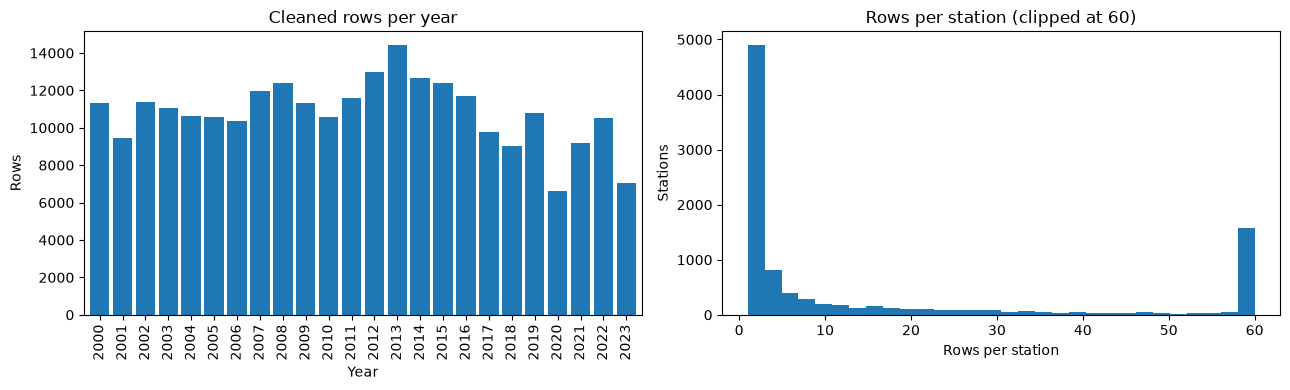

Stations: 9,940; median rows/station: 3


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
year_counts = df["date"].dt.year.value_counts().sort_index()
year_counts.plot(kind="bar", ax=axes[0], width=.85)
axes[0].set_title("Cleaned rows per year"); axes[0].set_xlabel("Year"); axes[0].set_ylabel("Rows")
site_counts = df.groupby("site_id").size().clip(upper=60)
axes[1].hist(site_counts, bins=30)
axes[1].set_title("Rows per station (clipped at 60)"); axes[1].set_xlabel("Rows per station"); axes[1].set_ylabel("Stations")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_b6_year_site.png"), dpi=200); plt.show()
print(f"Stations: {df['site_id'].nunique():,}; median rows/station: {df.groupby('site_id').size().median():.0f}")

**What we see → What we do about it:** There are about 7,000 to 14,000 rows per year, with a dip in 2020. Most stations have very few rows: the median is only 3, and 60% of stations have 5 or fewer, while one station has 6,426. Rows from the same station look alike, so a random split would put the same station in both train and test, and the model could just remember it. So we split by station.

## B7. Train / validation / test composition
Per country: % of rows in each `split`; overall counts; `split` vs `split_time` cross-tab; check that no station appears in both train and test.

In [16]:
display((pd.crosstab(df["country"], df["split"], normalize="index").mul(100).round(2)))
print("Overall station-split counts:")
display(df["split"].value_counts().rename("rows").to_frame())
print("Year-based split counts:")
display(df["split_time"].value_counts().rename("rows").to_frame())
print("Station split × year split (% rows):")
display(pd.crosstab(df["split"], df["split_time"], normalize="all").mul(100).round(2))
train_sites = set(df.loc[df["split"] == "train", "site_id"])
test_sites = set(df.loc[df["split"] == "test", "site_id"])
overlap = train_sites & test_sites
print(f"Stations shared by station-based train and test: {len(overlap)}")
assert len(overlap) == 0, "Leakage check failed: station appears in train and test"

split,test,train,val
country,,,
Canada,21.31,66.62,12.08
England,20.21,69.02,10.77
Ireland,20.55,70.93,8.52
USA,8.52,86.23,5.26


Overall station-split counts:


,rows
split,
train,181747
test,51973
val,26054


Year-based split counts:


,rows
split_time,
train,185094
test,53181
val,21499


Station split × year split (% rows):


split_time,test,train,val
split,,,
test,3.98,14.37,1.66
train,14.51,49.58,5.87
val,1.98,7.30,0.75


Stations shared by station-based train and test: 0


**What we see → What we do about it:** No station is in both train and test (the check in the code stops the notebook if one is). The split is about 70 / 10 / 20 for each country, except the USA, where only 8.5% of the rows are in the test set because there are few USA stations. The station split asks: does it work at a new place? The year split asks: does it work on later years? These are two different tests, so we do not mix their scores.

## B8. Seasonality
Mean target, dissolved oxygen and temperature by `month` (line plots). Explains the `month_sin` / `month_cos` features.

,target_mean,dissolved_oxygen_mean,temperature_mean
month,,,
1,91.129,10.286,6.727
2,91.784,10.127,6.639
3,91.570,10.186,7.855
4,91.448,9.922,10.082
5,90.262,9.347,12.488
6,89.411,8.653,14.734
7,88.588,8.337,15.851
8,88.525,8.226,15.733
9,88.644,8.352,13.971


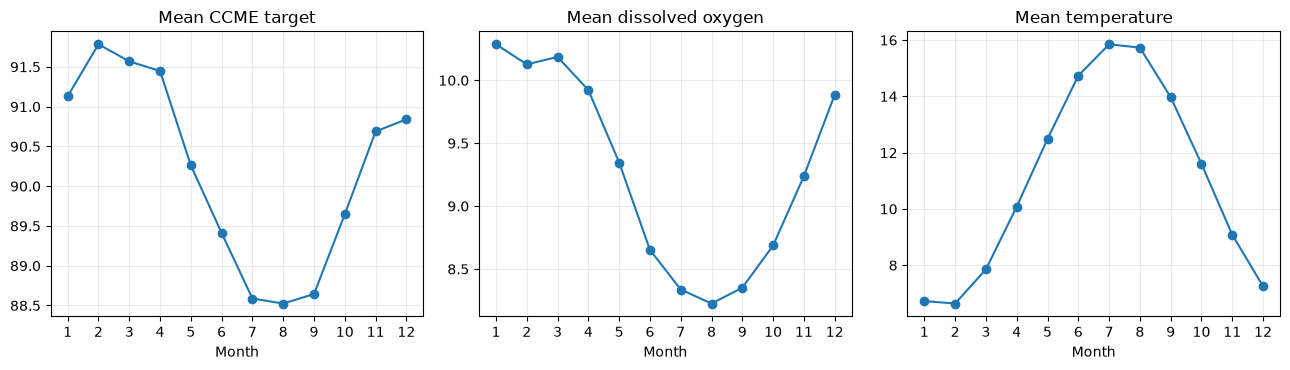

In [17]:
monthly = df.groupby("month").agg(
    target_mean=("target_ccme_value", "mean"),
    dissolved_oxygen_mean=("dissolved_oxygen_mg_l", "mean"),
    temperature_mean=("temperature_c", "mean"))
monthly = monthly.reindex(range(1, 13))
display(monthly.round(3))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col, title in zip(axes, monthly.columns, ["Mean CCME target", "Mean dissolved oxygen", "Mean temperature"]):
    ax.plot(monthly.index, monthly[col], marker="o")
    ax.set_title(title); ax.set_xlabel("Month"); ax.set_xticks(range(1,13)); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_b8_season.png"), dpi=200); plt.show()

**What we see → What we do about it:** The average score is lowest in summer (88.5 in July and August) and highest in winter (91.8 in February). Dissolved oxygen goes down in summer (8.2) and up in winter (10.3), while temperature goes the other way (15.8 °C in summer, 6.6 °C in winter). So the time of year matters. We turn the month into a sine and a cosine so that December and January are next to each other.

# Part C · Before vs after

## C1. Summary table
Rows, columns and % missing per parameter, raw vs cleaned, and rows per country raw vs cleaned.

In [18]:
clean_missing = df[PARAM_COLS].isna().mean().mul(100).round(2)
summary = pd.DataFrame({"dataset": ["raw", "cleaned"],
                        "rows": [raw_n, len(df)],
                        "columns": [raw_cols, df.shape[1]],
                        "mean_missing_percent_across_8_parameters": [raw_missing.mean(), clean_missing.mean()]})
display(summary)
raw_country_pct = raw_by_country.rename("raw_rows")
clean_country = df["country"].value_counts().rename("cleaned_rows")
display(pd.concat([raw_country_pct, clean_country], axis=1).fillna(0).astype(int))
display(pd.DataFrame({"raw_missing_percent": raw_missing, "cleaned_missing_percent": clean_missing}))

,dataset,rows,columns,mean_missing_percent_across_8_parameters
0,raw,2781980,14,0.0000
1,cleaned,259774,19,18.0425


,raw_rows,cleaned_rows
country,,
England,2129198,180082
USA,413814,6810
Ireland,235019,70282
Canada,3949,2600


,raw_missing_percent,cleaned_missing_percent
ammonia_mg_l,0.0,29.37
bod_mg_l,0.0,51.72
dissolved_oxygen_mg_l,0.0,22.43
orthophosphate_mg_l,0.0,5.65
ph,0.0,4.55
temperature_c,0.0,0.61
nitrogen_mg_l,0.0,6.23
nitrate_mg_l,0.0,23.78


**What we see → What we do about it:** After cleaning we have 259,774 rows in 4 countries. Most rows were removed because they were not surface water or were too old or had too few real measurements, and the fake filler values became missing. The table above shows the rows, columns and missing % before and after, and how each country changed.

## C2. Dissolved oxygen, raw vs cleaned (England rivers)
One side-by-side plot that shows the whole cleaning story: raw histogram with spike, cleaned histogram without.

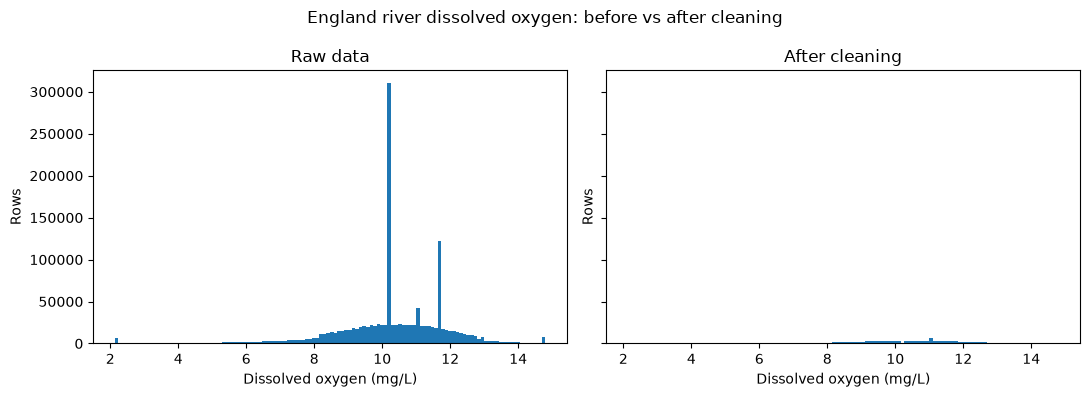

In [19]:
clean_do_eng = df.loc[(df["country"] == "England") & (df["waterbody_type"] == "River"), "dissolved_oxygen_mg_l"].dropna()
# Use a common range based on combined robust quantiles so the two panels are comparable.
combined = pd.concat([raw_do_eng.dropna(), clean_do_eng], ignore_index=True)
lo, hi = combined.quantile([0.005, 0.995])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, values, title in [(axes[0], raw_do_eng, "Raw data"), (axes[1], clean_do_eng, "After cleaning")]:
    ax.hist(values.dropna().clip(lo, hi), bins=120)
    ax.set_title(title); ax.set_xlabel("Dissolved oxygen (mg/L)"); ax.set_ylabel("Rows")
fig.suptitle("England river dissolved oxygen: before vs after cleaning")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "eda_c2_do_before_after.png"), dpi=200); plt.show()

**What we see → What we do about it:** Left is the raw data with its tall spike, right is the cleaned data without it. Both plots use the same x-range, so they can be compared directly. This one picture tells the whole cleaning story. The gaps that remain are filled later using the training data only.

**EDA summary:** The raw data had five problems: sewage and effluent samples that are not surface water, old records before 2000, exact copies, impossible values and fake filler numbers (for example dissolved oxygen 10.2 in 360,401 England rows). We removed or fixed all of them. The cleaned data has 259,774 rows from 9,940 stations, 2000 to 2023, and it is mostly England (69.3%) and Ireland (27.1%). Many values are missing, especially BOD (51.7%), ammonia (29.4%) and nitrate (23.8%). The score is stuck at 100 for 43.7% of the rows, so bad water is rare (0.8% Poor). The five parameters with the strongest link to the score (orthophosphate −0.93, ammonia, nitrogen, nitrate and BOD) are hidden from the model so that it cannot just recompute the formula. Most stations have very few rows (median 3), so we split by station, and we also test on later years. The score is a bit lower in summer, so we use month as a sine and a cosine.